# Slide 4: Approach and experiments

**Status: DRAFT for Jyoti's review. All numbers are preliminary until the team agrees on the setup.**

Question: how does the Hessian condition number κ affect convergence of gradient descent (GD) versus L-BFGS?

Approach
1. Same three datasets, same start, same stopping rule for both methods (README shared setup).
2. GD uses the best fixed step size, 2 / (λmin + λmax). L-BFGS uses a line search.
3. Count the same things for both: iterations to tolerance, gradient evaluations, final loss, final gradient norm, parameter error vs w* = (3, 2).
4. Compare with theory: GD should take about ln(tol/‖g0‖) / ln((κ−1)/(κ+1)) steps.

Drafted with AI assistance. Jyoti should read the code, re-run it and edit the wording before pushing.

## 1. Setup (from the README)

In [1]:
import numpy as np, pandas as pd, urllib.request, io, os
import matplotlib.pyplot as plt
from scipy.optimize import line_search, minimize

W_STAR = np.array([3.0, 2.0])
TOL = 1e-6
FILES = {"round_k1": 1, "moderate_k10": 10, "narrow_k100": 100}
URL = "https://raw.githubusercontent.com/priyavenugopalnair-debug/group7-optimizers/main/data/"

def load(name):
    """Try GitHub first, then local folders (data/, ../data/, current folder)."""
    try:
        raw = urllib.request.urlopen(URL + name + ".csv", timeout=10).read().decode()
        return pd.read_csv(io.StringIO(raw))
    except Exception:
        for d in ["data", "../data", "."]:
            p = os.path.join(d, name + ".csv")
            if os.path.exists(p):
                return pd.read_csv(p)
    raise FileNotFoundError(name)

data = {}
for name, k in FILES.items():
    df = load(name)
    data[name] = (df[["x1", "x2"]].values, df["y"].values)   # x1, x2 only, no bias
    X, y = data[name]
    lam = np.linalg.eigvalsh(X.T @ X / len(y))
    print(f"{name:13s} rows={len(y)}  eigenvalues={np.round(lam,4)}  kappa={lam[-1]/lam[0]:.1f}")

round_k1      rows=200  eigenvalues=[1. 1.]  kappa=1.0
moderate_k10  rows=200  eigenvalues=[0.1 1. ]  kappa=10.0


narrow_k100   rows=200  eigenvalues=[0.01 1.  ]  kappa=100.0


## 2. The two methods

**Problem object.** Counts gradient evaluations at *distinct* points. If the line search asks for the gradient at a point we already computed, it is not counted twice, so GD and L-BFGS are counted the same way.

**GD.** w ← w − α·g, with α = 2 / (λmin + λmax), stop when ‖g‖ < 1e-6.

**L-BFGS (written from scratch).** Keeps the last m = 10 pairs (s, y) where s = change in w and y = change in gradient. The two-loop recursion builds the direction −H⁻¹g from those pairs without ever forming H. The first step has no pairs, so it uses −g/‖g‖. The step length comes from a Wolfe line search (`scipy.optimize.line_search`).

In [2]:
class Problem:
    def __init__(self, X, y):
        self.X, self.y, self.n = X, y, len(y)
        self.cache, self.grad_evals = {}, 0
    def loss(self, w):
        r = self.X @ w - self.y
        return 0.5 * np.mean(r * r)
    def grad(self, w):
        key = np.asarray(w, float).tobytes()
        if key not in self.cache:
            self.grad_evals += 1
            self.cache[key] = self.X.T @ (self.X @ w - self.y) / self.n
        return self.cache[key].copy()

def run_gd(p, alpha, max_iter=200_000):
    w = np.zeros(2); g = p.grad(w); hist = [np.linalg.norm(g)]; it = 0
    while np.linalg.norm(g) >= TOL and it < max_iter:
        w = w - alpha * g; g = p.grad(w); it += 1; hist.append(np.linalg.norm(g))
    return w, it, hist

def run_lbfgs(p, m=10, max_iter=500):
    w = np.zeros(2); g = p.grad(w); S, Y = [], []; hist = [np.linalg.norm(g)]; it = 0
    while np.linalg.norm(g) >= TOL and it < max_iter:
        q = g.copy(); alphas = []
        for s, yv in reversed(list(zip(S, Y))):          # first loop (newest to oldest)
            a = (s @ q) / (yv @ s); alphas.append(a); q = q - a * yv
        q = q * (S[-1] @ Y[-1]) / (Y[-1] @ Y[-1]) if S else q / np.linalg.norm(g)   # initial scaling
        for (s, yv), a in zip(zip(S, Y), reversed(alphas)):   # second loop (oldest to newest)
            b = (yv @ q) / (yv @ s); q = q + s * (a - b)
        d = -q
        t = line_search(p.loss, p.grad, w, d, gfk=g)[0]
        if t is None: break
        w_new = w + t * d; g_new = p.grad(w_new)
        s, yv = w_new - w, g_new - g
        if yv @ s > 1e-30:
            S.append(s); Y.append(yv); S, Y = S[-m:], Y[-m:]
        w, g = w_new, g_new; it += 1; hist.append(np.linalg.norm(g))
    return w, it, hist

## 3. Run both methods on all three datasets

In [3]:
rows, hists = [], {}
for name, k in FILES.items():
    X, y = data[name]
    lam = np.linalg.eigvalsh(X.T @ X / len(y)); alpha = 2 / (lam[0] + lam[-1])
    for method in ["GD", "L-BFGS"]:
        p = Problem(X, y)
        w, it, h = run_gd(p, alpha) if method == "GD" else run_lbfgs(p)
        hists[(name, method)] = h
        rows.append({"dataset": name, "kappa": k, "method": method, "iterations": it,
                     "gradient evals": p.grad_evals, "final loss": p.loss(w),
                     "final ‖g‖": np.linalg.norm(p.grad(w)),
                     "‖w − w*‖": np.linalg.norm(w - W_STAR)})
res = pd.DataFrame(rows)
pd.options.display.float_format = "{:.3g}".format
res

,dataset,kappa,method,iterations,gradient evals,final loss,final ‖g‖,‖w − w*‖
0,round_k1,1,GD,1,2,5.7e-31,9.71e-16,9.16e-16
1,round_k1,1,L-BFGS,2,3,6.33e-30,3.53e-15,3.55e-15
2,moderate_k10,10,GD,75,76,3.98e-13,8.75e-07,1.05e-06
3,moderate_k10,10,L-BFGS,6,7,3.32e-18,9.79e-10,7.97e-09
4,narrow_k100,100,GD,746,747,4.96e-13,9.94e-07,1.19e-06
5,narrow_k100,100,L-BFGS,5,10,4.1e-16,2.86e-08,2.91e-08


## 4. Is GD getting a fair step size?
GD is the baseline, so it should not lose because of a bad step size. Below: the best fixed step vs two smaller ones, on κ = 100. A smaller step is only slower.

In [4]:
X, y = data["narrow_k100"]; lam = np.linalg.eigvalsh(X.T @ X / len(y))
best = 2 / (lam[0] + lam[-1])
fair = []
for label, a in [("best 2/(λmin+λmax)", best), ("half of best", best / 2), ("1/λmax", 1 / lam[-1])]:
    p = Problem(X, y); w, it, _ = run_gd(p, a)
    fair.append({"step rule": label, "alpha": a, "iterations": it, "gradient evals": p.grad_evals})
pd.DataFrame(fair)

,step rule,alpha,iterations,gradient evals
0,best 2/(λmin+λmax),1.98,746,747
1,half of best,0.99,996,997
2,1/λmax,1,986,987


## 5. Cross-check L-BFGS against scipy
Our from-scratch L-BFGS should behave like a trusted library. `L-BFGS-B` (maxcor = 10) is scipy's implementation. Exact counts can differ because the line searches differ.

In [5]:
chk = []
for name, k in FILES.items():
    X, y = data[name]; p = Problem(X, y)
    r = minimize(p.loss, np.zeros(2), jac=p.grad, method="L-BFGS-B",
                 options={"maxcor": 10, "gtol": TOL, "ftol": 0, "maxiter": 500})
    chk.append({"dataset": name, "kappa": k, "scipy iterations": r.nit,
                "scipy gradient evals": p.grad_evals, "‖w − w*‖": np.linalg.norm(r.x - W_STAR)})
pd.DataFrame(chk)

,dataset,kappa,scipy iterations,scipy gradient evals,‖w − w*‖
0,round_k1,1,2,3,4.09e-15
1,moderate_k10,10,6,7,7.97e-09
2,narrow_k100,100,5,8,5.54e-08


## 6. Measured vs predicted GD iterations
Theory: error factor per step r = (κ−1)/(κ+1) at the best step size, so steps ≈ floor(ln(tol/‖g0‖) / ln r) + 1. For κ = 1, r = 0 and one step lands on the answer.

In [6]:
pv = []
for name, k in FILES.items():
    X, y = data[name]; g0 = np.linalg.norm(X.T @ (0 - y) / len(y))
    r = (k - 1) / (k + 1)
    pred = 1 if r == 0 else int(np.floor(np.log(TOL / g0) / np.log(r))) + 1
    meas = int(res[(res.dataset == name) & (res.method == "GD")].iloc[0]["iterations"])
    pv.append({"dataset": name, "kappa": k, "error factor r": r, "predicted GD updates": pred, "measured GD updates": meas})
pd.DataFrame(pv)

,dataset,kappa,error factor r,predicted GD updates,measured GD updates
0,round_k1,1,0,1,1
1,moderate_k10,10,0.818,75,75
2,narrow_k100,100,0.98,746,746


## 7. Chart: gradient norm per iteration

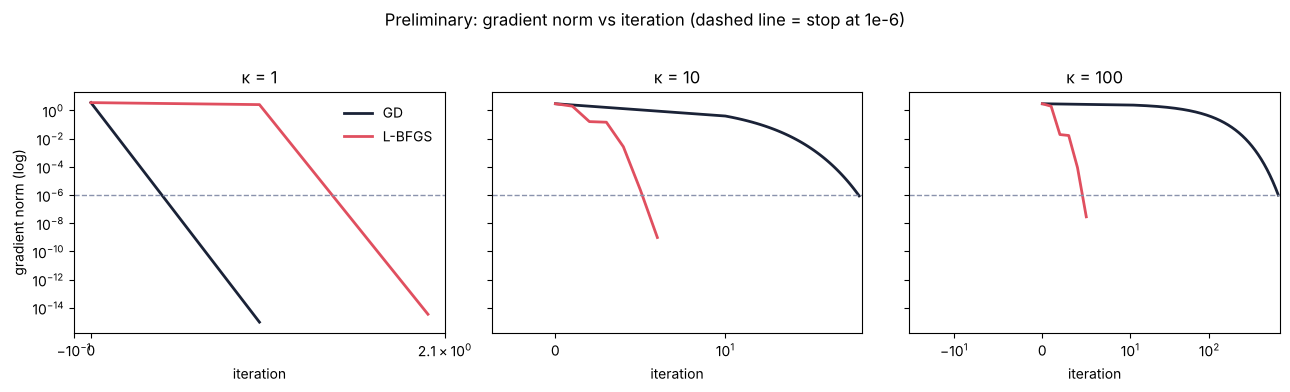

In [7]:
NAVY, CORAL = "#1A2237", "#E04F5F"
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (name, k) in zip(axes, FILES.items()):
    for method, c in [("GD", NAVY), ("L-BFGS", CORAL)]:
        h = np.maximum(hists[(name, method)], 1e-17)
        ax.plot(range(len(h)), h, color=c, lw=2, label=method)
    ax.axhline(TOL, color="#8A93AD", ls="--", lw=1)
    ax.set_yscale("log"); ax.set_xscale("symlog", linthresh=10)
    ax.set_title(f"κ = {k}"); ax.set_xlabel("iteration")
axes[0].set_ylabel("gradient norm (log)"); axes[0].legend(frameon=False)
fig.suptitle("Preliminary: gradient norm vs iteration (dashed line = stop at 1e-6)", y=1.02)
plt.tight_layout(); plt.show()

## 8. What this shows, and what it does not
**Shows (preliminary, noise-free, 2 parameters, full-batch):**
- GD iterations grow with κ and match the (κ−1)/(κ+1) prediction.
- L-BFGS needs about the same few iterations whichever κ we use.

**Does not show:**
- Anything about noisy or minibatch (stochastic) gradients, where L-BFGS is known to be unstable (Byrd et al. 2016). Our setup is full-batch GD, so "SGD" in the project title is **not** tested here. The team should decide whether to add a minibatch run or reword.
- Anything about larger models. With 2 parameters, L-BFGS keeping 10 pairs is more memory than the full 2×2 Hessian, so a memory comparison is not meaningful here.
- Wall-clock time. Counts of gradient evaluations are used instead.

**Open items for the team:** confirm the iteration and gradient-evaluation counting rule (distinct points here), and confirm `dataset_manifest.json` (the README mentions it but it is not in the repo).